# Análisis completo: 10 modelos x 4 variantes del dataset

Consolida y compara los **40 resultados de entrenamiento** (10 arquitecturas x 4 variantes del
manifiesto: `6clases_con_exclusion`, `5clases_con_exclusion`, `6clases_sin_excluir`,
`5clases_sin_excluir`). Lee únicamente lo que cada notebook de entrenamiento ya guardó en
`resultados/resultados_entrenamiento/<variante>/<modelo>/` -- no entrena ni evalúa nada de nuevo.

**Qué responde este análisis**
1. ¿Qué modelo es mejor, y con qué incertidumbre? (ranking con intervalos de confianza por
   *bootstrap* y probabilidad de ser el mejor -- no solo el valor puntual de una corrida).
2. ¿Cuánto cuesta (en F1) mantener la clase STB? (6 vs 5 clases)
3. ¿Sirve excluir las imágenes marcadas por baja calidad? (con vs sin exclusión)
4. ¿Qué familia de arquitecturas rinde mejor? (CNN, Transformer, híbrido, custom)
5. Insumo para elegir qué modelo(s) usar en la aplicación.

**Salvedades que condicionan la lectura de todo el notebook**
- **ACTUALIZADO 2026-10-14:** `6clases_con_exclusion` se lee ahora de `6_clases_con_exclusion_224` (corrida B, flujo idéntico al de las otras 3 variantes). La corrida A (imágenes originales) solo se usa en `analisis_replica_radimagenet.ipynb`. Las secciones en markdown que citan cifras fueron escritas con la corrida A: las cifras vigentes son las de las tablas/CSV generados.
- **Cada resultado es UNA sola corrida.** No hay semillas fijadas en el entrenamiento, así que se
  desconoce cuánto varía un mismo modelo entre dos corridas idénticas. Las diferencias pequeñas
  (del orden de 0.01-0.02 de F1) no se pueden distinguir del ruido de entrenamiento con estos datos.
  Está planificada una réplica de `6clases_con_exclusion` para cuantificarlo.
- **El tiempo de entrenamiento no es comparable** entre `6clases_con_exclusion` (pipeline con
  imágenes a resolución completa) y las otras 3 variantes (`dataset_final_224`, pre-redimensionado).
  Las métricas de clasificación sí son comparables: el modelo ve exactamente los mismos píxeles.
- **El tiempo de inferencia guardado incluye la carga de datos**, así que no mide solo el modelo.
  No se debe citar como costo de la arquitectura (Sección 9).
- **Los test sets no son idénticos entre variantes**: quitar STB elimina sus imágenes, y excluir por
  calidad quita unas pocas más. Dentro de una misma variante, los 10 modelos sí comparten el test set
  exacto (se verifica en la Sección 1).

## 0. Configuración

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import chi2, wilcoxon

RESULTS_DIR = Path("../resultados/resultados_entrenamiento")
OUTPUT_DIR = Path("../resultados/comparacion_variantes")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
RNG_SEED = 42
N_BOOT = 2000

VARIANT_DIRS = {
    "6clases_con_exclusion": RESULTS_DIR / "6_clases_con_exclusion_224",  # corrida B: dataset pre-redimensionado, mismo flujo que las otras 3 variantes (la corrida A, con imágenes originales, queda solo en analisis_replica_radimagenet.ipynb)
    "5clases_con_exclusion": RESULTS_DIR / "5_clases_con_exclusion",
    "6clases_sin_excluir": RESULTS_DIR / "6_clases_sin_exclusion",
    "5clases_sin_excluir": RESULTS_DIR / "5_clases_sin_exclusion",
}
VARIANTS = list(VARIANT_DIRS)
PIPELINE_LENTO = set()  # ya no hay variantes con flujo distinto

NICE_NAMES = {
    "vgg16_bn": "VGG16",
    "mobilenetv3_small_100": "MobileNetV3",
    "resnet50": "ResNet50",
    "efficientnet_b0": "EfficientNetB0",
    "swin_tiny_patch4_window7_224": "Swin-Tiny",
    "vit_base_patch16_224": "ViT-Base",
    "deit_base_patch16_224": "DeiT-Base",
    "coatnet_0_rw_224": "CoAtNet",
    "maxvit_tiny_tf_224": "MaxViT",
    "custom_cnn_transformer": "Custom",
}
FAMILIA = {
    "VGG16": "CNN", "ResNet50": "CNN", "MobileNetV3": "CNN", "EfficientNetB0": "CNN",
    "ViT-Base": "Transformer", "DeiT-Base": "Transformer", "Swin-Tiny": "Transformer",
    "CoAtNet": "Híbrido", "MaxViT": "Híbrido",
    "Custom": "Custom",
}
CLASSES_6 = ["COVID-19", "Normal", "Pneumonia", "Silicosis", "STB", "Tuberculosis"]
CLASSES_5 = ["COVID-19", "Normal", "Pneumonia", "Silicosis", "Tuberculosis"]

def save_fig(name):
    plt.savefig(OUTPUT_DIR / f"{name}.png", dpi=600, bbox_inches="tight")
    plt.savefig(OUTPUT_DIR / f"{name}.pdf", bbox_inches="tight")

## 1. Cargar y consolidar

Por variante se leen TODOS los `comparacion_modelos.csv` bajo su carpeta (ese archivo se acumula en
la carpeta compartida de Drive durante el entrenamiento, así que puede haber quedado guardado dentro
de la carpeta de *otro* modelo) y se descartan duplicados por `(model_name, variant_name)`. El modelo
se identifica por el contenido de cada fila y por el prefijo del nombre de archivo, nunca por el
nombre de la carpeta (que tiene erratas como `swiin` o `swing`).

Además se verifica que, dentro de cada variante, los 10 modelos usaron el mismo test set en el mismo
orden -- requisito para poder comparar imagen a imagen (McNemar, bootstrap pareado).

In [2]:
def load_variant(variant_dir):
    frames = [pd.read_csv(f) for f in variant_dir.glob("*/comparacion_modelos.csv")]
    df = pd.concat(frames, ignore_index=True)
    dup = df[df.duplicated(["model_name", "variant_name"], keep=False)]
    if len(dup):
        conflict = dup.groupby("model_name")["f1_macro"].nunique()
        conflict = conflict[conflict > 1]
        if len(conflict):
            print(f"  ATENCIÓN: valores distintos para el mismo modelo en {variant_dir.name}: {list(conflict.index)}")
    df = df.drop_duplicates(["model_name", "variant_name"], keep="last").reset_index(drop=True)
    df["label"] = df["model_name"].map(NICE_NAMES).fillna(df["model_name"])
    return df

def load_predictions(variant_dir):
    preds = {}
    for f in variant_dir.glob("*/*_predicciones.npz"):
        label = NICE_NAMES.get(f.name.split("__")[0], f.name.split("__")[0])
        d = np.load(f)
        preds[label] = {"y_true": d["y_true"], "y_pred": d["y_pred"], "y_prob": d["y_prob"]}
    return preds

def load_per_class(variant_dir):
    frames = []
    for f in variant_dir.glob("*/*_metricas_por_clase.csv"):
        label = NICE_NAMES.get(f.name.split("__")[0], f.name.split("__")[0])
        d = pd.read_csv(f); d["label"] = label; frames.append(d)
    return pd.concat(frames, ignore_index=True)

all_variants = {v: load_variant(d) for v, d in VARIANT_DIRS.items()}
preds_by_variant = {v: load_predictions(d) for v, d in VARIANT_DIRS.items()}
per_class_by_variant = {v: load_per_class(d) for v, d in VARIANT_DIRS.items()}
consolidado = pd.concat(all_variants.values(), ignore_index=True)
consolidado["familia"] = consolidado["label"].map(FAMILIA)
consolidado.to_csv(OUTPUT_DIR / "consolidado_40_resultados.csv", index=False)

for v in VARIANTS:
    df = all_variants[v]
    ref_label = sorted(preds_by_variant[v])[0]
    ref = preds_by_variant[v][ref_label]["y_true"]
    same = all(np.array_equal(ref, p["y_true"]) for p in preds_by_variant[v].values())
    print(f"{v}: {len(df)} modelos | n_test={df['n_test_images'].unique().tolist()} | "
          f"mismo test set en los {len(preds_by_variant[v])} modelos: {same}")
    assert len(df) == 10 and same, v
print(f"\nTotal de resultados: {len(consolidado)}")

6clases_con_exclusion: 10 modelos | n_test=[3457] | mismo test set en los 10 modelos: True
5clases_con_exclusion: 10 modelos | n_test=[3346] | mismo test set en los 10 modelos: True
6clases_sin_excluir: 10 modelos | n_test=[3470] | mismo test set en los 10 modelos: True
5clases_sin_excluir: 10 modelos | n_test=[3359] | mismo test set en los 10 modelos: True

Total de resultados: 40


## 2. Ranking por variante

Valor puntual de **una** corrida por modelo. La Sección 3 pone incertidumbre sobre esto.

F1 macro y puesto por variante (ordenado por F1 medio de las 4):
variant_name    6clases_con_exclusion  5clases_con_exclusion  6clases_sin_excluir  5clases_sin_excluir  puesto_6clases_con_exclusion  puesto_5clases_con_exclusion  puesto_6clases_sin_excluir  puesto_5clases_sin_excluir  F1_medio  puesto_medio
label                                                                                                                                                                                                                                             
ViT-Base                        0.765                  0.878                0.763                0.859                             2                             1                           2                           4     0.816          2.25
DeiT-Base                       0.759                  0.868                0.768                0.867                             4                             2                           1                

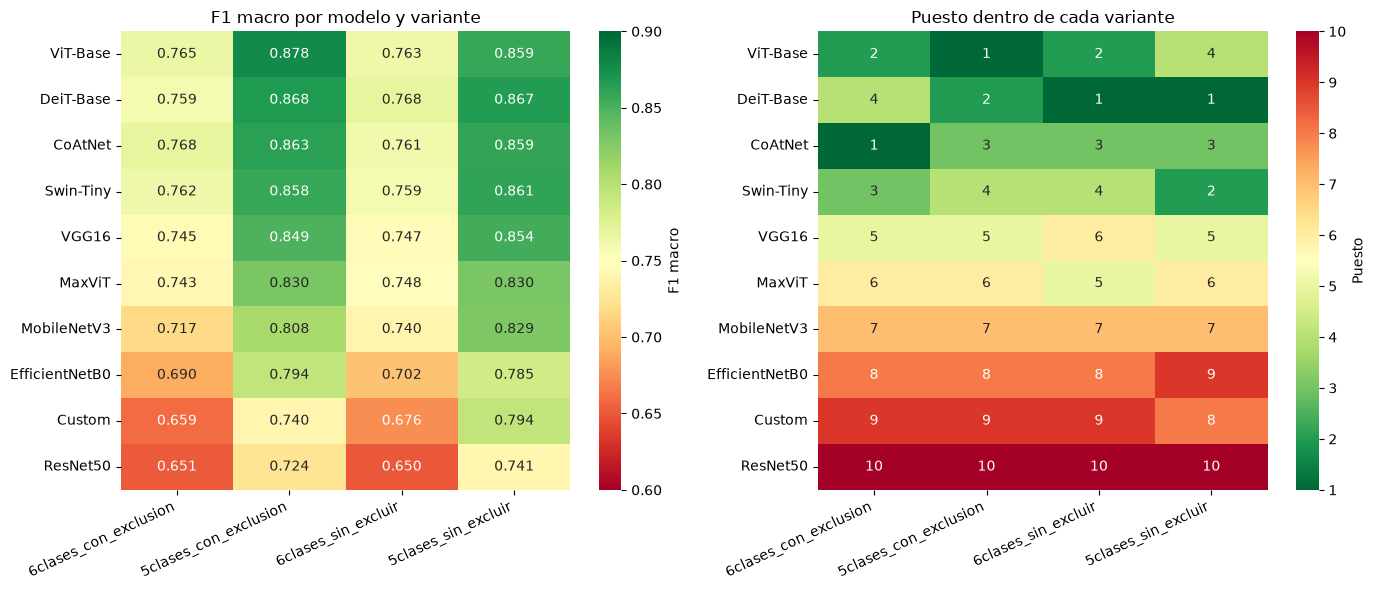

In [3]:
f1 = consolidado.pivot(index="label", columns="variant_name", values="f1_macro")[VARIANTS]
rank = f1.rank(ascending=False).astype(int)
orden = f1.mean(axis=1).sort_values(ascending=False).index
f1, rank = f1.loc[orden], rank.loc[orden]

resumen = f1.copy()
for v in VARIANTS:
    resumen[f"puesto_{v}"] = rank[v]
resumen["F1_medio"] = f1.mean(axis=1)
resumen["puesto_medio"] = rank.mean(axis=1)
resumen.to_csv(OUTPUT_DIR / "f1_y_puestos_por_variante.csv")
print("F1 macro y puesto por variante (ordenado por F1 medio de las 4):")
print(resumen.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.heatmap(f1, annot=True, fmt=".3f", cmap="RdYlGn", vmin=0.6, vmax=0.9, ax=axes[0], cbar_kws={"label": "F1 macro"})
axes[0].set_title("F1 macro por modelo y variante"); axes[0].set_ylabel(""); axes[0].set_xlabel("")
sns.heatmap(rank, annot=True, fmt="d", cmap="RdYlGn_r", ax=axes[1], cbar_kws={"label": "Puesto"})
axes[1].set_title("Puesto dentro de cada variante"); axes[1].set_ylabel(""); axes[1].set_xlabel("")
for ax in axes:
    ax.set_xticklabels(ax.get_xticklabels(), rotation=25, ha="right")
plt.tight_layout(); save_fig("ranking_heatmaps"); plt.show()

## 3. Ranking con incertidumbre: *bootstrap* pareado sobre el test set

Un solo valor de F1 no dice si dos modelos realmente se distinguen. Aquí se re-muestrea el test set
con reemplazo (`N_BOOT` veces) y se recalcula el F1 macro de **todos** los modelos sobre la **misma**
muestra (pareado, válido porque comparten el test set). De ahí salen:
- el intervalo de confianza al 95% del F1 de cada modelo,
- la **probabilidad de que cada modelo sea el mejor** y de que quede en el top 3.

Limitación: mide solo la incertidumbre de *muestreo del test set*; **no** incluye la variación entre
corridas de entrenamiento (para eso hacen falta las réplicas).

In [4]:
def macro_f1_from_codes(codes, k):
    cm = np.bincount(codes, minlength=k * k).reshape(k, k)
    tp = np.diag(cm).astype(float)
    fp = cm.sum(axis=0) - tp
    fn = cm.sum(axis=1) - tp
    denom = 2 * tp + fp + fn
    f1c = np.divide(2 * tp, denom, out=np.zeros_like(tp), where=denom > 0)
    return f1c.mean()

def bootstrap_variant(preds, k, n_boot, seed):
    labels = sorted(preds)
    y_true = preds[labels[0]]["y_true"]
    n = len(y_true)
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, n, size=(n_boot, n))
    yt = y_true[idx]
    boot = {}
    for lbl in labels:
        yp = preds[lbl]["y_pred"][idx]
        codes = yt * k + yp
        boot[lbl] = np.array([macro_f1_from_codes(codes[b], k) for b in range(n_boot)])
    boot_df = pd.DataFrame(boot)
    ranks = boot_df.rank(axis=1, ascending=False)
    out = pd.DataFrame({
        "F1_punto": [macro_f1_from_codes(y_true * k + preds[l]["y_pred"], k) for l in labels],
        "IC95_inf": boot_df.quantile(0.025).values,
        "IC95_sup": boot_df.quantile(0.975).values,
        "P_ser_el_mejor": (ranks == 1).mean().values,
        "P_top3": (ranks <= 3).mean().values,
        "puesto_medio": ranks.mean().values,
    }, index=labels)
    return out.sort_values("F1_punto", ascending=False), boot_df

boot_results, boot_samples = {}, {}
for v in VARIANTS:
    k = 5 if "5clases" in v else 6
    boot_results[v], boot_samples[v] = bootstrap_variant(preds_by_variant[v], k, N_BOOT, RNG_SEED)
    boot_results[v].to_csv(OUTPUT_DIR / f"bootstrap_{v}.csv")
    print(f"=== {v} ===")
    print(boot_results[v].round(3).to_string())
    print()

=== 6clases_con_exclusion ===
                F1_punto  IC95_inf  IC95_sup  P_ser_el_mejor  P_top3  puesto_medio
CoAtNet            0.768     0.747     0.787           0.446   0.878         1.997
ViT-Base           0.765     0.744     0.784           0.294   0.806         2.356
Swin-Tiny          0.762     0.741     0.781           0.148   0.710         2.810
DeiT-Base          0.759     0.738     0.780           0.106   0.520         3.248
VGG16              0.745     0.723     0.767           0.007   0.062         5.156
MaxViT             0.743     0.723     0.763           0.000   0.022         5.450
MobileNetV3        0.717     0.695     0.737           0.000   0.000         6.988
EfficientNetB0     0.690     0.667     0.710           0.000   0.000         8.000
Custom             0.659     0.638     0.680           0.000   0.000         9.220
ResNet50           0.651     0.629     0.672           0.000   0.000         9.774



=== 5clases_con_exclusion ===
                F1_punto  IC95_inf  IC95_sup  P_ser_el_mejor  P_top3  puesto_medio
ViT-Base           0.878     0.865     0.891           0.942   1.000         1.062
DeiT-Base          0.868     0.854     0.882           0.049   0.965         2.212
CoAtNet            0.863     0.848     0.877           0.009   0.734         3.092
Swin-Tiny          0.858     0.844     0.873           0.000   0.277         3.777
VGG16              0.849     0.834     0.864           0.000   0.024         4.869
MaxViT             0.830     0.815     0.845           0.000   0.000         5.991
MobileNetV3        0.808     0.792     0.823           0.000   0.000         7.037
EfficientNetB0     0.794     0.776     0.810           0.000   0.000         7.961
Custom             0.740     0.723     0.758           0.000   0.000         9.028
ResNet50           0.724     0.707     0.742           0.000   0.000         9.972



=== 6clases_sin_excluir ===
                F1_punto  IC95_inf  IC95_sup  P_ser_el_mejor  P_top3  puesto_medio
DeiT-Base          0.768     0.748     0.787           0.507   0.916         1.822
ViT-Base           0.763     0.742     0.783           0.222   0.746         2.638
CoAtNet            0.761     0.741     0.782           0.170   0.666         2.900
Swin-Tiny          0.759     0.738     0.779           0.088   0.518         3.400
MaxViT             0.748     0.727     0.767           0.004   0.074         5.350
VGG16              0.747     0.725     0.767           0.008   0.074         5.468
MobileNetV3        0.740     0.721     0.760           0.000   0.008         6.423
EfficientNetB0     0.702     0.682     0.721           0.000   0.000         8.007
Custom             0.676     0.655     0.696           0.000   0.000         8.999
ResNet50           0.650     0.629     0.672           0.000   0.000         9.992



=== 5clases_sin_excluir ===
                F1_punto  IC95_inf  IC95_sup  P_ser_el_mejor  P_top3  puesto_medio
DeiT-Base          0.867     0.854     0.881           0.718   0.972         1.404
Swin-Tiny          0.861     0.846     0.874           0.116   0.720         2.786
CoAtNet            0.859     0.845     0.873           0.084   0.580         3.186
ViT-Base           0.859     0.845     0.872           0.060   0.518         3.358
VGG16              0.854     0.839     0.868           0.022   0.210         4.272
MaxViT             0.830     0.815     0.845           0.000   0.000         6.484
MobileNetV3        0.829     0.815     0.845           0.000   0.000         6.511
Custom             0.794     0.778     0.811           0.000   0.000         8.127
EfficientNetB0     0.785     0.769     0.800           0.000   0.000         8.872
ResNet50           0.741     0.724     0.757           0.000   0.000        10.000



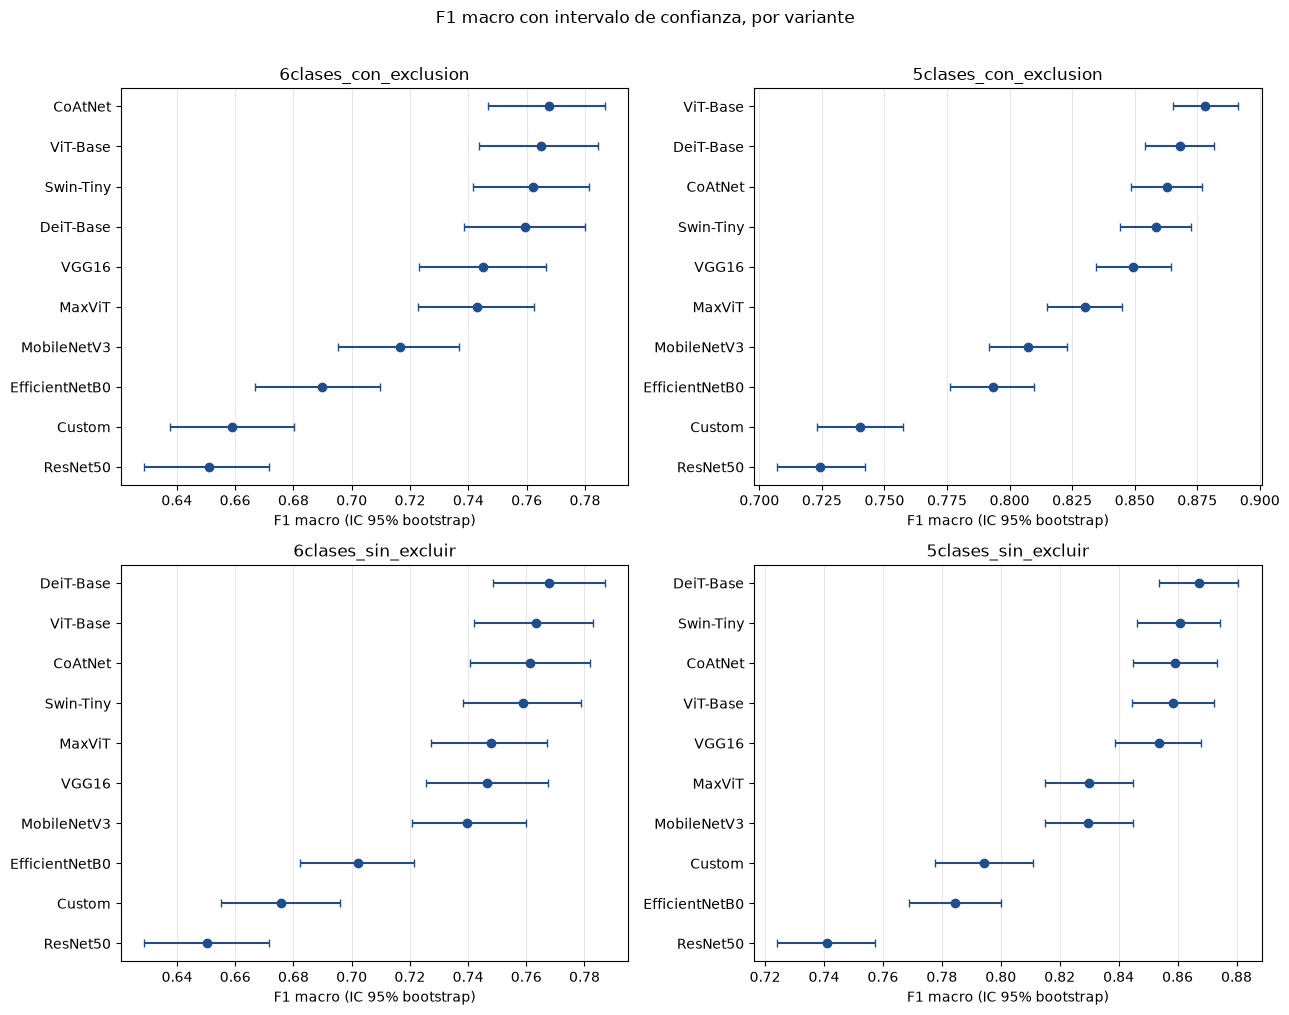

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10), sharex=False)
for ax, v in zip(axes.ravel(), VARIANTS):
    r = boot_results[v].iloc[::-1]
    y = np.arange(len(r))
    ax.errorbar(r["F1_punto"], y, xerr=[r["F1_punto"] - r["IC95_inf"], r["IC95_sup"] - r["F1_punto"]],
                fmt="o", capsize=3, color="#1f4e8c")
    ax.set_yticks(y); ax.set_yticklabels(r.index)
    ax.set_title(v); ax.set_xlabel("F1 macro (IC 95% bootstrap)"); ax.grid(axis="x", alpha=0.3)
plt.suptitle("F1 macro con intervalo de confianza, por variante", y=1.01)
plt.tight_layout(); save_fig("bootstrap_intervalos"); plt.show()

### 3.1 Ranking consolidado

Las variantes de 6 y de 5 clases son **tareas distintas** (distinto número de clases), así que se
consolidan por separado: puesto medio en las 2 variantes de 6 clases, y en las 2 de 5 clases.

In [6]:
rows = []
for grupo, vs in [("6 clases", ["6clases_con_exclusion", "6clases_sin_excluir"]),
                  ("5 clases", ["5clases_con_exclusion", "5clases_sin_excluir"])]:
    sub = pd.DataFrame({
        "F1_medio": f1[vs].mean(axis=1),
        "puesto_medio": rank[vs].mean(axis=1),
        "P_mejor_medio": pd.concat([boot_results[v]["P_ser_el_mejor"] for v in vs], axis=1).mean(axis=1),
        "P_top3_medio": pd.concat([boot_results[v]["P_top3"] for v in vs], axis=1).mean(axis=1),
    }).sort_values("puesto_medio")
    sub.insert(0, "grupo", grupo)
    rows.append(sub)
consolidado_ranking = pd.concat(rows).reset_index(names="modelo")
consolidado_ranking = consolidado_ranking.merge(
    consolidado.drop_duplicates("label")[["label", "familia", "total_params", "size_mb"]],
    left_on="modelo", right_on="label").drop(columns="label")
consolidado_ranking.to_csv(OUTPUT_DIR / "ranking_consolidado.csv", index=False)
for g in ["6 clases", "5 clases"]:
    print(f"--- {g} (promedio de las 2 variantes) ---")
    print(consolidado_ranking[consolidado_ranking["grupo"] == g].drop(columns="grupo").round(3).to_string(index=False))
    print()

--- 6 clases (promedio de las 2 variantes) ---
        modelo  F1_medio  puesto_medio  P_mejor_medio  P_top3_medio     familia  total_params  size_mb
       CoAtNet     0.765           2.0          0.308         0.772     Híbrido      26671176  101.742
      ViT-Base     0.764           2.0          0.258         0.776 Transformer      85803270  327.313
     DeiT-Base     0.764           2.5          0.306         0.718 Transformer      85803270  327.313
     Swin-Tiny     0.760           3.5          0.118         0.614 Transformer      27523968  104.996
         VGG16     0.746           5.5          0.007         0.068         CNN     134293574  512.289
        MaxViT     0.746           5.5          0.002         0.048     Híbrido      30406606  115.992
   MobileNetV3     0.728           7.0          0.000         0.004         CNN       1524006    5.814
EfficientNetB0     0.696           8.0          0.000         0.000         CNN       4015234   15.317
        Custom     0.667  

## 4. El efecto de quitar STB (6 clases a 5 clases)

Mismos 10 modelos, mismo criterio de exclusión; solo cambia si la clase STB está. Ojo: el F1 macro
de 5 clases promedia sobre una clase menos, y justo es la peor -- parte de la mejora es aritmética
(la clase más difícil sale del promedio) y parte puede ser que el modelo mejore en las demás.
La Sección 4.1 separa ambas cosas.

Delta F1 macro (5 clases - 6 clases):
                con_exclusion  sin_excluir
label                                     
ViT-Base                0.113        0.095
DeiT-Base               0.109        0.099
CoAtNet                 0.095        0.098
Swin-Tiny               0.096        0.102
VGG16                   0.104        0.107
MaxViT                  0.087        0.082
MobileNetV3             0.091        0.090
EfficientNetB0          0.104        0.083
Custom                  0.081        0.119
ResNet50                0.073        0.090

con_exclusion: media +0.095 | rango [+0.073, +0.113] | mejoran 10/10
sin_excluir: media +0.096 | rango [+0.082, +0.119] | mejoran 10/10


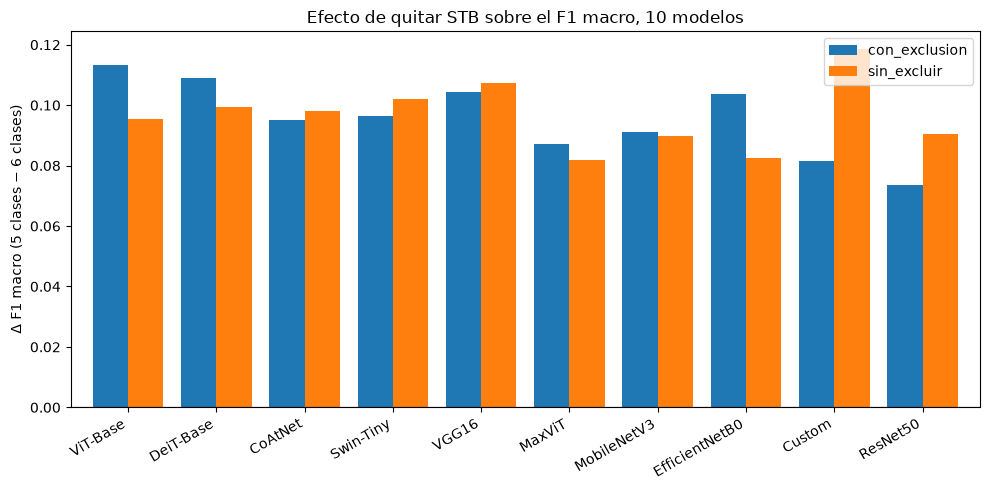

In [7]:
def delta(b, a):
    return (f1[b] - f1[a])

stb_con = delta("5clases_con_exclusion", "6clases_con_exclusion")
stb_sin = delta("5clases_sin_excluir", "6clases_sin_excluir")
stb = pd.DataFrame({"con_exclusion": stb_con, "sin_excluir": stb_sin}).loc[orden]
stb.to_csv(OUTPUT_DIR / "efecto_quitar_stb.csv")
print("Delta F1 macro (5 clases - 6 clases):")
print(stb.round(3).to_string())
print()
for c in stb:
    print(f"{c}: media {stb[c].mean():+.3f} | rango [{stb[c].min():+.3f}, {stb[c].max():+.3f}] | "
          f"mejoran {int((stb[c] > 0).sum())}/10")

fig, ax = plt.subplots(figsize=(10, 5))
stb.plot(kind="bar", ax=ax, width=0.8)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("Δ F1 macro (5 clases − 6 clases)"); ax.set_xlabel("")
ax.set_title("Efecto de quitar STB sobre el F1 macro, 10 modelos")
plt.xticks(rotation=30, ha="right"); plt.tight_layout(); save_fig("efecto_quitar_stb"); plt.show()

### 4.1 ¿Cuánto de esa mejora es aritmética y cuánto es real?

El F1 macro de 5 clases promedia sobre una clase menos, y la que sale es la peor. Eso sube el promedio
**aunque los modelos no mejoren en nada**. Se separa así, usando el F1 por clase de cada modelo:
- *efecto de composición*: F1 promedio de las 5 clases comunes **dentro del problema de 6 clases**
  menos el F1 macro de 6 clases (es solo sacar STB del promedio);
- *efecto real*: F1 macro de 5 clases menos ese F1 restringido (cuánto mejoran las clases restantes
  cuando STB ya no está en el problema).

In [8]:
def descomponer(v6, v5):
    pc6 = per_class_by_variant[v6]
    restringido = pc6[pc6["class"].isin(CLASSES_5)].groupby("label")["f1"].mean()
    completo = pc6.groupby("label")["f1"].mean()
    assert np.allclose(completo.reindex(f1.index), f1[v6], atol=1e-6), "F1 macro != promedio de F1 por clase"
    out = pd.DataFrame({
        "F1_macro_6": f1[v6],
        "F1_5_clases_comunes_en_problema_6": restringido.reindex(f1.index),
        "F1_macro_5": f1[v5],
    })
    out["efecto_composicion"] = out["F1_5_clases_comunes_en_problema_6"] - out["F1_macro_6"]
    out["efecto_real"] = out["F1_macro_5"] - out["F1_5_clases_comunes_en_problema_6"]
    return out.loc[orden]

dec_con = descomponer("6clases_con_exclusion", "5clases_con_exclusion")
dec_sin = descomponer("6clases_sin_excluir", "5clases_sin_excluir")
dec_con.to_csv(OUTPUT_DIR / "descomposicion_quitar_stb_con_exclusion.csv")
dec_sin.to_csv(OUTPUT_DIR / "descomposicion_quitar_stb_sin_excluir.csv")
for nombre, d in [("con exclusión", dec_con), ("sin excluir", dec_sin)]:
    print(f"--- {nombre} ---")
    print(d.round(3).to_string())
    tot = d["F1_macro_5"].mean() - d["F1_macro_6"].mean()
    print(f"Mejora media total: {tot:+.3f} = composición {d['efecto_composicion'].mean():+.3f} "
          f"+ real {d['efecto_real'].mean():+.3f}\n")

--- con exclusión ---
                F1_macro_6  F1_5_clases_comunes_en_problema_6  F1_macro_5  efecto_composicion  efecto_real
label                                                                                                     
ViT-Base             0.765                              0.818       0.878               0.053        0.060
DeiT-Base            0.759                              0.814       0.868               0.055        0.054
CoAtNet              0.768                              0.819       0.863               0.052        0.043
Swin-Tiny            0.762                              0.814       0.858               0.052        0.044
VGG16                0.745                              0.811       0.849               0.066        0.038
MaxViT               0.743                              0.781       0.830               0.038        0.049
MobileNetV3          0.717                              0.768       0.808               0.051        0.040
EfficientNetB0 

## 5. El efecto de excluir por calidad (con exclusión vs. sin excluir)

**Tamaño real del cambio**: la exclusión quita muy pocas imágenes del dataset final (se calcula abajo
desde los manifiestos). Además cambia el test set (unas pocas imágenes menos), así que la comparación
no es sobre exactamente las mismas imágenes de test. Con un cambio tan chico, lo esperable es que el
efecto medido esté dominado por el ruido de entrenamiento.

In [9]:
man_dir = Path("../dataset_final/manifiestos")
try:
    sin6 = pd.read_csv(man_dir / "manifiesto_6clases_sin_excluir.csv")
    con6 = pd.read_csv(man_dir / "manifiesto_6clases_con_exclusion.csv")
    quitadas = sin6[~sin6["path_final"].isin(set(con6["path_final"]))]
    print(f"Imágenes que quita la exclusión por calidad: {len(quitadas)} de {len(sin6)} "
          f"({100 * len(quitadas) / len(sin6):.2f}%)")
    print("Por split:", quitadas["split"].value_counts().to_dict())
    print("Por clase:", quitadas["target_class"].value_counts().to_dict())
except FileNotFoundError:
    print("No se encontró dataset_final/manifiestos localmente; se omite este conteo.")

Imágenes que quita la exclusión por calidad: 78 de 23105 (0.34%)
Por split: {'train': 51, 'val': 14, 'test': 13}
Por clase: {'Tuberculosis': 27, 'COVID-19': 26, 'Pneumonia': 17, 'Normal': 8}


Delta F1 macro (con exclusión - sin excluir); positivo = excluir ayuda:
                6_clases  5_clases
label                             
ViT-Base           0.002     0.020
DeiT-Base         -0.009     0.001
CoAtNet            0.007     0.004
Swin-Tiny          0.003    -0.002
VGG16             -0.001    -0.004
MaxViT            -0.005     0.000
MobileNetV3       -0.023    -0.022
EfficientNetB0    -0.012     0.009
Custom            -0.017    -0.054
ResNet50           0.001    -0.016

6_clases: media -0.0055 | desv. est. 0.0096 | positivos 4/10 | Wilcoxon p=0.193
5_clases: media -0.0066 | desv. est. 0.0203 | positivos 5/10 | Wilcoxon p=0.557


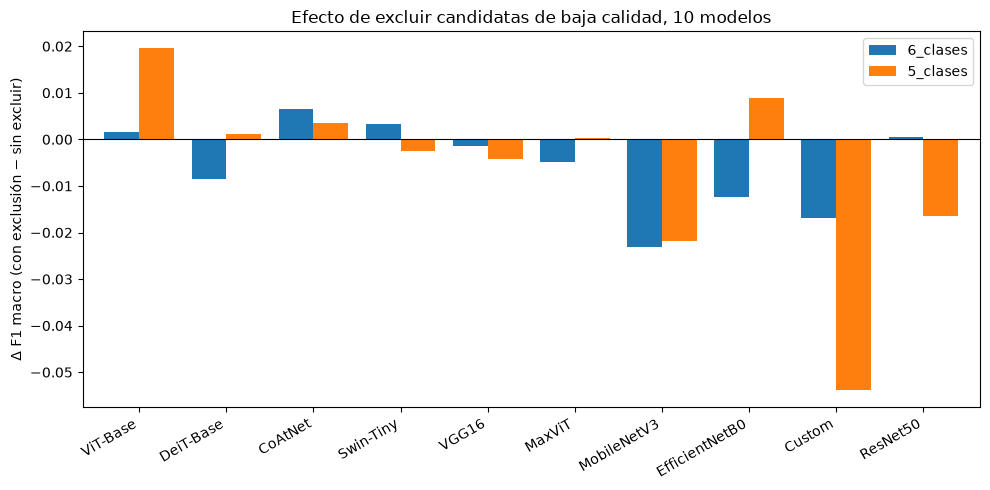

In [10]:
cal_6 = delta("6clases_con_exclusion", "6clases_sin_excluir")
cal_5 = delta("5clases_con_exclusion", "5clases_sin_excluir")
cal = pd.DataFrame({"6_clases": cal_6, "5_clases": cal_5}).loc[orden]
cal.to_csv(OUTPUT_DIR / "efecto_exclusion_calidad.csv")
print("Delta F1 macro (con exclusión - sin excluir); positivo = excluir ayuda:")
print(cal.round(3).to_string())
print()
for c in cal:
    d = cal[c]
    stat, p = wilcoxon(d)
    print(f"{c}: media {d.mean():+.4f} | desv. est. {d.std():.4f} | positivos {int((d > 0).sum())}/10 | "
          f"Wilcoxon p={p:.3f}")

fig, ax = plt.subplots(figsize=(10, 5))
cal.plot(kind="bar", ax=ax, width=0.8)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("Δ F1 macro (con exclusión − sin excluir)"); ax.set_xlabel("")
ax.set_title("Efecto de excluir candidatas de baja calidad, 10 modelos")
plt.xticks(rotation=30, ha="right"); plt.tight_layout(); save_fig("efecto_exclusion_calidad"); plt.show()

### 5.1 Estimación indirecta del ruido de entrenamiento

Como la exclusión por calidad cambia tan pocas imágenes (78, 0.34%), su efecto verdadero sobre el F1
debería ser casi nulo. Si es así, la dispersión de las diferencias de arriba es básicamente la
**variabilidad entre corridas de entrenamiento** (sin semilla fija, dos corridas del mismo modelo
difieren). Si cada corrida tiene desviación estándar `s`, la diferencia entre dos corridas tiene
desviación `s*sqrt(2)`, así que `s` se estima como (desviación de las diferencias) / sqrt(2).

Es una estimación **aproximada** (supone efecto cero y los test sets difieren en 13 imágenes), pero da
un orden de magnitud para saber qué diferencias entre modelos se pueden tomar en serio. La medida
directa vendrá de las réplicas planificadas de `6clases_con_exclusion`.

In [11]:
diffs = pd.concat([cal["6_clases"], cal["5_clases"]])
s_all = diffs.std() / np.sqrt(2)
diffs_sin_custom = diffs.drop("Custom")
s_sin_custom = diffs_sin_custom.std() / np.sqrt(2)
mad = 1.4826 * np.median(np.abs(diffs - np.median(diffs))) / np.sqrt(2)
print(f"Desviación estándar por corrida (estimada), 20 diferencias: {s_all:.4f}")
print(f"  sin el modelo Custom: {s_sin_custom:.4f}")
print(f"  estimación robusta (MAD): {mad:.4f}")
print(f"Diferencias entre dos modelos menores a ~{2 * np.sqrt(2) * s_sin_custom:.3f} de F1 macro "
      "no se distinguen del ruido de entrenamiento (aprox. 2 desviaciones de la diferencia).")
print("\nMayores diferencias absolutas observadas (con vs sin exclusión):")
print(diffs.abs().sort_values(ascending=False).head(5).round(3).to_string())

Desviación estándar por corrida (estimada), 20 diferencias: 0.0109
  sin el modelo Custom: 0.0076
  estimación robusta (MAD): 0.0063
Diferencias entre dos modelos menores a ~0.021 de F1 macro no se distinguen del ruido de entrenamiento (aprox. 2 desviaciones de la diferencia).

Mayores diferencias absolutas observadas (con vs sin exclusión):
label
Custom         0.054
MobileNetV3    0.023
MobileNetV3    0.022
ViT-Base       0.020
Custom         0.017


## 6. F1 por clase: ¿quitar STB ayuda también a las demás clases?

Agregado sobre los 10 modelos (promedio de F1 por clase). Para las 5 clases en común se compara su F1
con y sin STB en el problema.

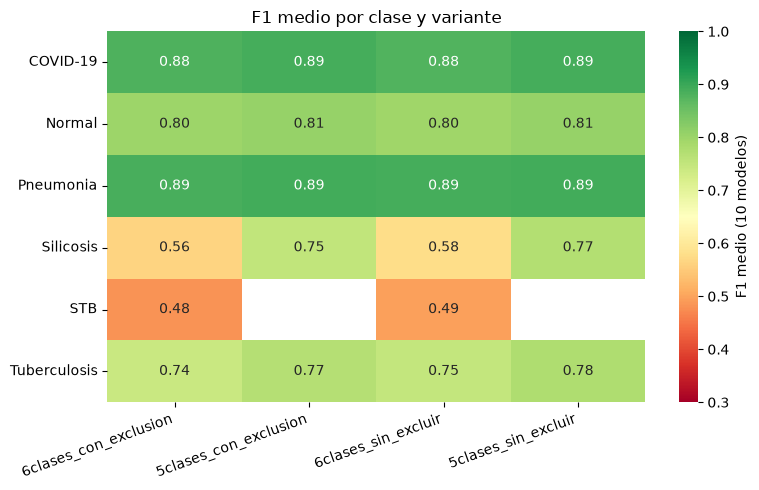

Cambio en el F1 medio de cada clase al quitar STB (5 clases - 6 clases):
              con_exclusion  sin_excluir
class                                   
COVID-19              0.007        0.011
Normal                0.008        0.011
Pneumonia             0.005        0.002
Silicosis             0.189        0.195
Tuberculosis          0.025        0.027

F1 medio de STB en las variantes de 6 clases: {'6clases_con_exclusion': 0.483, '6clases_sin_excluir': 0.494}


In [12]:
def mean_f1_by_class(v):
    return per_class_by_variant[v].groupby("class")["f1"].mean()

clase_var = pd.DataFrame({v: mean_f1_by_class(v) for v in VARIANTS}).reindex(CLASSES_6)
clase_var.to_csv(OUTPUT_DIR / "f1_medio_por_clase_y_variante.csv")

fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(clase_var, annot=True, fmt=".2f", cmap="RdYlGn", vmin=0.3, vmax=1, ax=ax,
            cbar_kws={"label": "F1 medio (10 modelos)"})
ax.set_title("F1 medio por clase y variante"); ax.set_xlabel(""); ax.set_ylabel("")
plt.xticks(rotation=20, ha="right"); plt.tight_layout(); save_fig("f1_medio_por_clase"); plt.show()

comunes = [c for c in CLASSES_5]
efecto_clases = pd.DataFrame({
    "con_exclusion": clase_var.loc[comunes, "5clases_con_exclusion"] - clase_var.loc[comunes, "6clases_con_exclusion"],
    "sin_excluir": clase_var.loc[comunes, "5clases_sin_excluir"] - clase_var.loc[comunes, "6clases_sin_excluir"],
})
efecto_clases.to_csv(OUTPUT_DIR / "efecto_quitar_stb_por_clase.csv")
print("Cambio en el F1 medio de cada clase al quitar STB (5 clases - 6 clases):")
print(efecto_clases.round(3).to_string())
print()
print("F1 medio de STB en las variantes de 6 clases:",
      clase_var.loc["STB", ["6clases_con_exclusion", "6clases_sin_excluir"]].round(3).to_dict())

## 7. Por familia de arquitectura

variant_name  6clases_con_exclusion  5clases_con_exclusion  6clases_sin_excluir  5clases_sin_excluir
familia                                                                                             
CNN                           0.701                  0.794                0.710                0.802
Transformer                   0.762                  0.868                0.763                0.862
Híbrido                       0.755                  0.846                0.755                0.845
Custom                        0.659                  0.740                0.676                0.794

(CNN: VGG16, ResNet50, MobileNetV3, EfficientNetB0 | Transformer: ViT, DeiT, Swin | Híbrido: CoAtNet, MaxViT | Custom: 1 modelo)


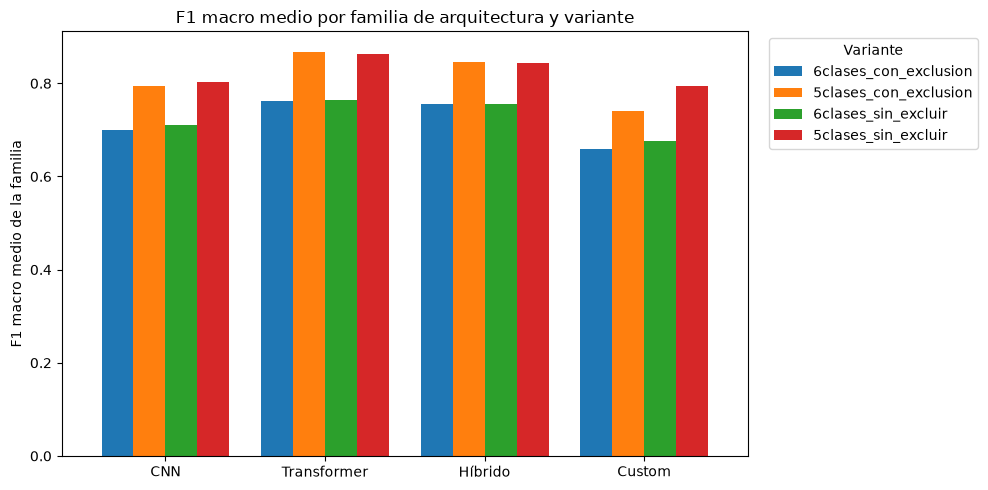

In [13]:
fam = consolidado.groupby(["familia", "variant_name"])["f1_macro"].mean().unstack()[VARIANTS]
fam = fam.loc[["CNN", "Transformer", "Híbrido", "Custom"]]
fam.to_csv(OUTPUT_DIR / "f1_medio_por_familia.csv")
print(fam.round(3).to_string())
print("\n(CNN: VGG16, ResNet50, MobileNetV3, EfficientNetB0 | Transformer: ViT, DeiT, Swin | "
      "Híbrido: CoAtNet, MaxViT | Custom: 1 modelo)")

fig, ax = plt.subplots(figsize=(10, 5))
fam.plot(kind="bar", ax=ax, width=0.8)
ax.set_ylabel("F1 macro medio de la familia"); ax.set_xlabel("")
ax.set_title("F1 macro medio por familia de arquitectura y variante")
ax.legend(title="Variante", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=0); plt.tight_layout(); save_fig("f1_por_familia"); plt.show()

## 8. Significancia: McNemar sobre el top 5 de cada variante

Compara, imagen por imagen, en cuáles acierta un modelo y falla el otro. Se hacen 10 comparaciones por
variante; sin corrección, alguna saldría "significativa" por azar. Por eso se reporta también el
p-valor ajustado por **Holm** (control del error por familia de comparaciones, dentro de cada variante).

In [14]:
def mcnemar_test(y_true, pred_a, pred_b):
    ca, cb = pred_a == y_true, pred_b == y_true
    b, c = int((ca & ~cb).sum()), int((~ca & cb).sum())
    if b + c == 0:
        return b, c, float("nan")
    stat = (abs(b - c) - 1) ** 2 / (b + c)
    return b, c, 1 - chi2.cdf(stat, df=1)

def holm(pvals):
    p = np.array(pvals, dtype=float)
    order = np.argsort(p)
    adj = np.empty_like(p)
    running = 0.0
    m = len(p)
    for rank_i, i in enumerate(order):
        running = max(running, (m - rank_i) * p[i])
        adj[i] = min(1.0, running)
    return adj

all_mc = []
for v in VARIANTS:
    top5 = boot_results[v].index[:5].tolist()
    rows = []
    for i in range(5):
        for j in range(i + 1, 5):
            a, bb = top5[i], top5[j]
            b, c, p = mcnemar_test(preds_by_variant[v][a]["y_true"],
                                   preds_by_variant[v][a]["y_pred"], preds_by_variant[v][bb]["y_pred"])
            rows.append({"variante": v, "modelo_A": a, "modelo_B": bb, "A_acierta_B_falla": b,
                         "A_falla_B_acierta": c, "p_valor": p})
    df = pd.DataFrame(rows)
    df["p_Holm"] = holm(df["p_valor"].fillna(1.0))
    df["significativo_sin_corregir"] = df["p_valor"] < 0.05
    df["significativo_Holm"] = df["p_Holm"] < 0.05
    all_mc.append(df)
mc = pd.concat(all_mc, ignore_index=True)
mc.to_csv(OUTPUT_DIR / "mcnemar_top5_4_variantes.csv", index=False)
for v in VARIANTS:
    print(f"=== {v}: top 5 = {boot_results[v].index[:5].tolist()} ===")
    print(mc[mc["variante"] == v][["modelo_A", "modelo_B", "p_valor", "p_Holm",
                                    "significativo_sin_corregir", "significativo_Holm"]].round(4).to_string(index=False))
    print()

=== 6clases_con_exclusion: top 5 = ['CoAtNet', 'ViT-Base', 'Swin-Tiny', 'DeiT-Base', 'VGG16'] ===
 modelo_A  modelo_B  p_valor  p_Holm  significativo_sin_corregir  significativo_Holm
  CoAtNet  ViT-Base   0.7397  1.0000                       False               False
  CoAtNet Swin-Tiny   0.9609  1.0000                       False               False
  CoAtNet DeiT-Base   0.8476  1.0000                       False               False
  CoAtNet     VGG16   0.0621  0.4971                       False               False
 ViT-Base Swin-Tiny   0.6519  1.0000                       False               False
 ViT-Base DeiT-Base   0.9214  1.0000                       False               False
 ViT-Base     VGG16   0.0264  0.2638                        True               False
Swin-Tiny DeiT-Base   0.7598  1.0000                       False               False
Swin-Tiny     VGG16   0.0665  0.4971                       False               False
DeiT-Base     VGG16   0.0359  0.3234                

## 9. Costo computacional

**Qué sí se puede comparar entre arquitecturas**: parámetros y tamaño en disco (propiedades del modelo).

**Qué NO se debe citar como costo de la arquitectura**:
- *Tiempo de inferencia guardado*: el cronómetro arranca antes de recorrer el `test_loader`, por lo que
  incluye leer y decodificar las imágenes. Evidencia: en `6clases_con_exclusion` los 10 modelos dan
  26-31 ms sin importar si tienen 1.5M o 134M de parámetros (es el costo de cargar la imagen). Hace
  falta un benchmark aparte con el tensor ya en memoria, usando los checkpoints guardados.
- *Tiempo de entrenamiento* entre `6clases_con_exclusion` y las demás variantes (pipeline distinto).

Parámetros, tamaño y tiempo de entrenamiento (pipeline rápido) -- variante 5clases_con_exclusion:
                    familia  total_params  size_mb  f1_macro  entrenamiento_h
label                                                                        
ViT-Base        Transformer      85802501  327.311     0.878            1.652
DeiT-Base       Transformer      85802501  327.311     0.868            1.942
CoAtNet             Híbrido      26670407  101.740     0.863            0.755
Swin-Tiny       Transformer      27523199  104.993     0.858            0.642
VGG16                   CNN     134289477  512.274     0.849            0.867
MaxViT              Híbrido      30406093  115.990     0.830            0.997
MobileNetV3             CNN       1522981    5.810     0.808            0.405
EfficientNetB0          CNN       4013953   15.312     0.794            0.420
Custom               Custom       6060101   23.117     0.740            0.558
ResNet50                CNN      23518277   

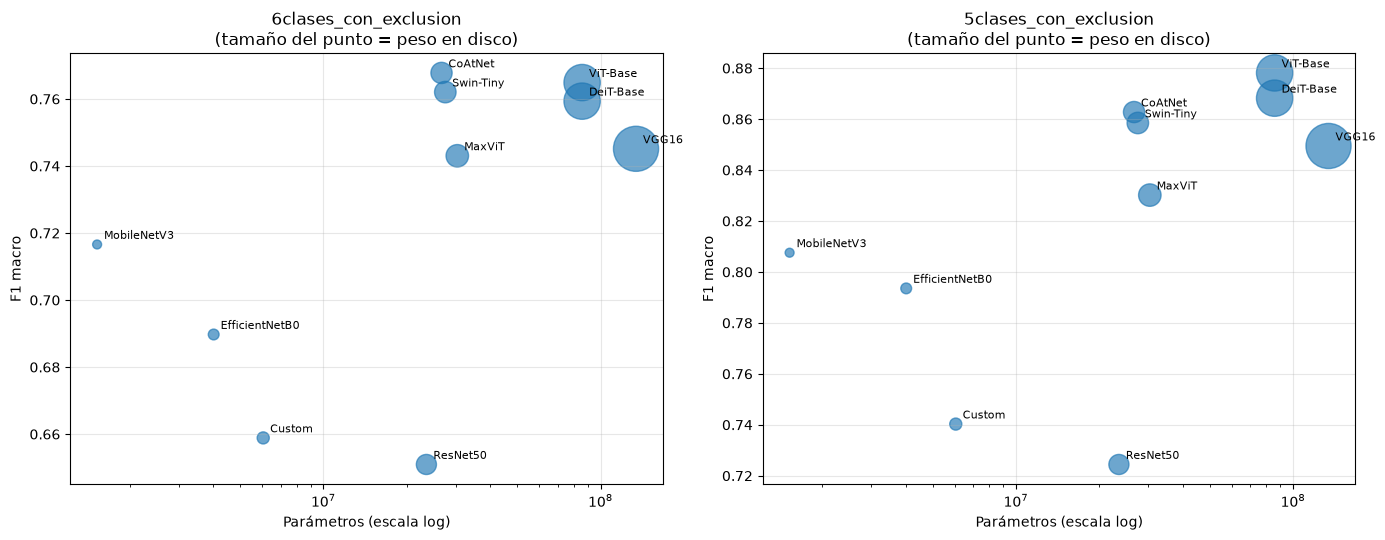

In [15]:
costo = consolidado[consolidado["variant_name"] == "5clases_con_exclusion"].set_index("label")[
    ["familia", "total_params", "size_mb", "f1_macro", "total_training_time_s"]].loc[orden]
costo["entrenamiento_h"] = costo["total_training_time_s"] / 3600
costo = costo.drop(columns="total_training_time_s")
costo.to_csv(OUTPUT_DIR / "costo_y_f1_5clases_con_exclusion.csv")
print("Parámetros, tamaño y tiempo de entrenamiento (pipeline rápido) -- variante 5clases_con_exclusion:")
print(costo.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, v in zip(axes, ["6clases_con_exclusion", "5clases_con_exclusion"]):
    d = consolidado[consolidado["variant_name"] == v]
    ax.scatter(d["total_params"], d["f1_macro"], s=d["size_mb"] * 2 + 30, alpha=0.65)
    for _, r in d.iterrows():
        ax.annotate(r["label"], (r["total_params"], r["f1_macro"]), fontsize=8, xytext=(5, 4), textcoords="offset points")
    ax.set_xscale("log"); ax.set_xlabel("Parámetros (escala log)"); ax.set_ylabel("F1 macro")
    ax.set_title(f"{v}\n(tamaño del punto = peso en disco)"); ax.grid(alpha=0.3)
plt.tight_layout(); save_fig("f1_vs_parametros"); plt.show()

## 10. Candidatos para la aplicación

Resumen para decidir qué modelo(s) servir. No decide por sí solo: el criterio final (qué variante, uno o
varios modelos) depende de cómo se defina el uso previsto. Se muestran, por grupo de variantes, los
modelos con mejor puesto medio junto a su costo de despliegue.

In [16]:
for g in ["6 clases", "5 clases"]:
    sub = consolidado_ranking[consolidado_ranking["grupo"] == g].head(6)
    print(f"--- Top 6, {g} ---")
    print(sub[["modelo", "familia", "F1_medio", "puesto_medio", "P_mejor_medio", "P_top3_medio",
               "total_params", "size_mb"]].round(3).to_string(index=False))
    print()

--- Top 6, 6 clases ---
   modelo     familia  F1_medio  puesto_medio  P_mejor_medio  P_top3_medio  total_params  size_mb
  CoAtNet     Híbrido     0.765           2.0          0.308         0.772      26671176  101.742
 ViT-Base Transformer     0.764           2.0          0.258         0.776      85803270  327.313
DeiT-Base Transformer     0.764           2.5          0.306         0.718      85803270  327.313
Swin-Tiny Transformer     0.760           3.5          0.118         0.614      27523968  104.996
    VGG16         CNN     0.746           5.5          0.007         0.068     134293574  512.289
   MaxViT     Híbrido     0.746           5.5          0.002         0.048      30406606  115.992

--- Top 6, 5 clases ---
   modelo     familia  F1_medio  puesto_medio  P_mejor_medio  P_top3_medio  total_params  size_mb
DeiT-Base Transformer     0.868           1.5          0.384         0.968      85803270  327.313
 ViT-Base Transformer     0.868           2.5          0.501         

## 12. Sensibilidad del F1 a las imágenes de prueba con duplicado intra-fuente o paciente repartido

Quita del test set las imágenes de `imagenes_con_fuga_potencial.csv` (mismo pHash dentro de una fuente, o paciente de SilicoData en más de un split) y recalcula el F1 macro de cada modelo. Si el cambio es mínimo, esas imágenes no inflan los resultados. Reemplaza al CSV generado el 2026-10-09 (que usaba la corrida A de `6clases_con_exclusion`).


In [17]:
from sklearn.metrics import f1_score
fuga = pd.read_csv(OUTPUT_DIR / 'imagenes_con_fuga_potencial.csv')
fuga = fuga[fuga['cruza_splits']]  # solo las que tienen pareja en OTRO conjunto
fuga['clave'] = fuga['path_final'].str.replace('\\', '/').str.split('/').str[-1]
man_dir = Path('../dataset_final/manifiestos')
MAN = {'6clases_con_exclusion': 'manifiesto_6clases_con_exclusion.csv', '5clases_con_exclusion': 'manifiesto_5clases_con_exclusion.csv',
       '6clases_sin_excluir': 'manifiesto_6clases_sin_excluir.csv', '5clases_sin_excluir': 'manifiesto_5clases_sin_excluir.csv'}
filas = []
for v in VARIANTS:
    man = pd.read_csv(man_dir / MAN[v]); test = man[man['split'] == 'test'].reset_index(drop=True)
    clases = CLASSES_6 if v.startswith('6') else CLASSES_5
    assert (test['target_class'].map({c: i for i, c in enumerate(clases)}).values == next(iter(preds_by_variant[v].values()))['y_true']).all(), v
    quitar = test['path_final'].str.replace('\\', '/').str.split('/').str[-1].isin(set(fuga['clave'])).values
    for lab, pr in preds_by_variant[v].items():
        f_all = f1_score(pr['y_true'], pr['y_pred'], average='macro')
        f_cl = f1_score(pr['y_true'][~quitar], pr['y_pred'][~quitar], average='macro')
        filas.append({'variante': v, 'modelo': lab, 'n_test': len(quitar), 'n_quitadas': int(quitar.sum()), 'f1_completo': f_all, 'f1_limpio': f_cl, 'delta': f_cl - f_all})
sens = pd.DataFrame(filas); sens.to_csv(OUTPUT_DIR / 'sensibilidad_test_limpio.csv', index=False)
print(sens.groupby('variante').agg(n_quitadas=('n_quitadas', 'first'), delta_medio=('delta', 'mean'), delta_abs_max=('delta', lambda s: s.abs().max())).round(4))


                       n_quitadas  delta_medio  delta_abs_max
variante                                                     
5clases_con_exclusion          12       0.0002         0.0019
5clases_sin_excluir            12      -0.0003         0.0013
6clases_con_exclusion          12      -0.0003         0.0018
6clases_sin_excluir            12      -0.0003         0.0016
